# 01 — First contact with the pic0rick

Companion notebook to *Meet the pic0rick* (`docs/substack/01-meet-the-pic0rick.md`).

* pic0rick python library **v0.1.8**, firmware **v0.1.11** (`-DDSP` RP2350 build).
* Runs **offline** by default on a capture recorded with the real board
  (`docs/data/dsp_captures/`). Set `LIVE = True` to talk to your own board.

In [1]:
# --- common setup: find the repo, import the pic0rick library, pin the version
import sys, pathlib
import numpy as np
import matplotlib.pyplot as plt

REPO = next(p for p in pathlib.Path.cwd().resolve().parents if (p / "python" / "pic0rick").is_dir())
sys.path.insert(0, str(REPO / "python"))
import pic0rick

WRITTEN_FOR = "0.1.8"   # pic0rick python library version this notebook was written against
print("pic0rick python library:", pic0rick.__version__, "(notebook written for", WRITTEN_FOR + ")")
if pic0rick.__version__ != WRITTEN_FOR:
    print("WARNING: library version differs -- the API may have moved, check python/Readme.md")

FIG = pathlib.Path("../images"); FIG.mkdir(exist_ok=True)
DATA = REPO / "docs" / "data"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.grid": True, "grid.alpha": 0.3})

LIVE = False   # set True with a pic0rick (firmware -DDSP build, v0.1.11+) plugged in

pic0rick python library: 0.1.8 (notebook written for 0.1.8)


## 1. Open the port and ask the board who it is

`Pic0rick()` auto-detects the USB CDC port (`/dev/ttyACM*`, `COM*`, `tty.usbmodem*`).
`version()` parses the firmware's `version` report; `status()` returns the DSP build's status block.

In [2]:
from pic0rick import dsp

if LIVE:
    from pic0rick.device import Pic0rick
    probe = Pic0rick(verbose=False)
    info = probe.version()
    print(info["raw"])
    st = probe.status()
    print(dsp.describe_status(st))
else:
    print("offline: status block recorded from an RP2350 pic0rick, firmware 0.1.11\n")
    print((DATA / "dsp_captures" / "raw" / "status.txt").read_text())

offline: status block recorded from an RP2350 pic0rick, firmware 0.1.11

pic0rick status
  board/package    pic0rick / RP2350A
  firmware         0.1.11
  dsp backend      f32-rfft-hilbert
  cmsis-dsp        1.17.0
  acquisition      4096 samples @ 60 MS/s
  pulser           armed
  pulse (ns)       neg 96 / damp 6000 / pos 96, neg-first
  dac / scale      50 / 512.0
  stream           off @ 0 Hz
  dropped frames   0
  DSP stage times (us):
      preprocess   0
      forward_fft  0
      mask         0
      inverse_fft  0
      magnitude    0
      alaw         0
  dsp_us / worst   0 / 0 (ok)
  max rates (Hz)   envelope 50, alaw 70


## 2. One raw frame

The DSP build answers `read_raw` with a binary frame: a 64-byte header (sequence, sample
rate, pulse settings, CRC32) followed by 8000 unsigned 10-bit samples at 60 MS/s.

In [3]:
import json

if LIVE:
    probe.set_gain(50)
    probe.configure_pulse(negative_ns=96, damp_ns=6000, positive_ns=96, order="neg-first")
    probe.arm_pulser()
    frame = probe.read_raw()
    probe.disarm_pulser()
    header = {k: getattr(frame.header, k) for k in ("sequence", "sample_count", "sample_rate_hz",
                                                     "negative_ns", "damp_ns", "positive_ns")}
    raw = frame.samples()
else:
    header = json.loads((DATA / "dsp_captures" / "raw" / "header.json").read_text())
    raw = np.load(DATA / "dsp_captures" / "raw" / "raw.npy")

print(json.dumps({k: header[k] for k in ("sequence", "sample_count", "sample_rate_hz",
                                          "negative_ns", "damp_ns", "positive_ns")}, indent=1))
print("samples:", raw.dtype, raw.shape, "min", raw.min(), "max", raw.max(), "mean %.1f" % raw.mean())

{
 "sequence": 91,
 "sample_count": 8000,
 "sample_rate_hz": 60000000,
 "negative_ns": 96,
 "damp_ns": 6000,
 "positive_ns": 96
}
samples: uint16 (8000,) min 0 max 1023 mean 549.6


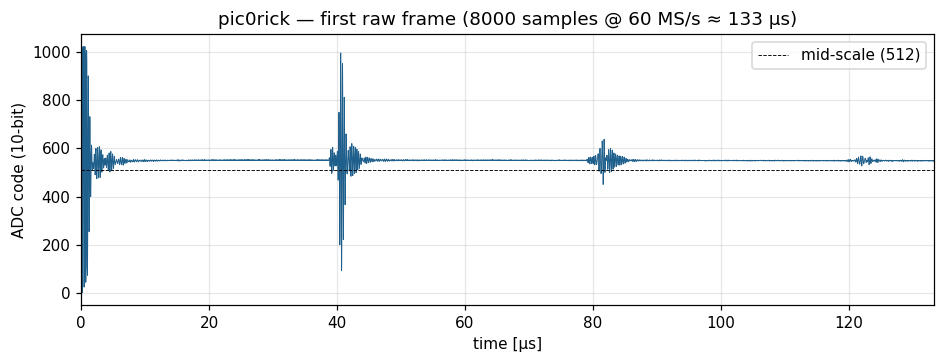

In [4]:
fs = 60e6
t_us = np.arange(raw.size) / fs * 1e6

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(t_us, raw, lw=0.6, color="#1f5f8b")
ax.axhline(512, color="k", lw=0.6, ls="--", label="mid-scale (512)")
ax.set(xlabel="time [µs]", ylabel="ADC code (10-bit)", xlim=(0, t_us[-1]),
       title="pic0rick — first raw frame (8000 samples @ 60 MS/s ≈ 133 µs)")
ax.legend(loc="upper right")
fig.savefig(FIG / "01-first-frame.png")

## 3. Sanity checks for a freshly assembled board

* **Mid-scale near 512** with no signal — the ADC is biased correctly.
* **The transmit pulse ("main bang")** at t≈0 saturates the front end: proof the pulser fired.
* **Something after it** — echoes from your transducer / target.

In [5]:
quiet = raw[-1500:]           # tail of the record, far from the main bang
bang = raw[:300]
print("baseline mean  : %.1f codes (ideal 512)" % quiet.mean())
print("baseline noise : %.2f codes rms" % quiet.std())
print("main bang span : %d .. %d codes" % (bang.min(), bang.max()))
print("pulser fired?  :", "yes" if bang.max() - bang.min() > 500 else "NO - check the pulser/HV boards")

baseline mean  : 549.0 codes (ideal 512)
baseline noise : 3.35 codes rms
main bang span : 0 .. 1023 codes
pulser fired?  : yes
